Homework 6, problem 3, part c

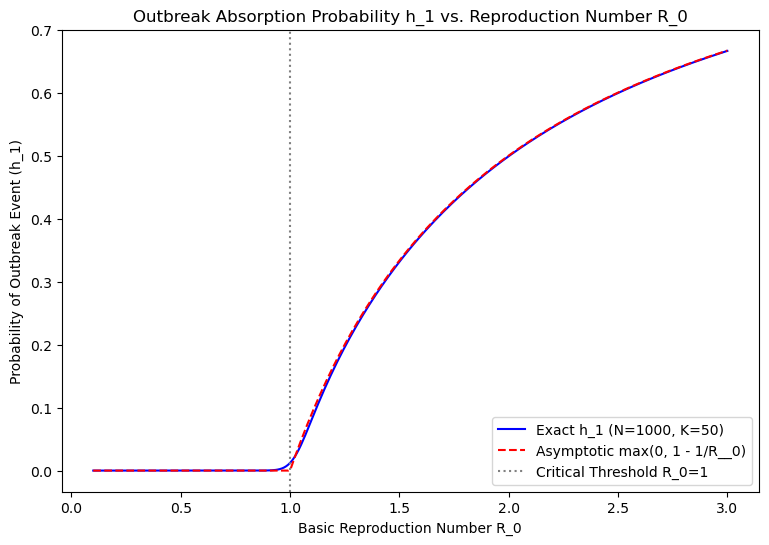

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
N = 1000
K = 50
R0_vals = np.linspace(0.1, 3.0, 300)
h1_exact = []

for R0 in R0_vals: # calculate exact absorption probability
    # calculate q_k / p_k
    k_idx = np.arange(1, K)
    ratios = N / (R0 * (N - k_idx))
    
    # calculate log-rho
    log_rho = np.cumsum(np.log(ratios))
    
    log_rho = np.insert(log_rho, 0, 0.0)
    rho = np.exp(log_rho)
    
    h1_exact.append(1.0 / np.sum(rho))

h1_exact = np.array(h1_exact)
h1_approx = np.maximum(0, 1 - 1/R0_vals)

# visualization
plt.figure(figsize = (9, 6))
plt.plot(R0_vals, h1_exact, 'b-', label = f'Exact h_1 (N={N}, K={K})')
plt.plot(R0_vals, h1_approx, 'r--', label = r'Asymptotic max(0, 1 - 1/R__0)')
plt.axvline(x=1.0, color='gray', linestyle = ':', label = 'Critical Threshold R_0=1')
plt.title('Outbreak Absorption Probability h_1 vs. Reproduction Number R_0')
plt.xlabel('Basic Reproduction Number R_0')
plt.ylabel('Probability of Outbreak Event (h_1)')
plt.legend()
plt.show()

Part d

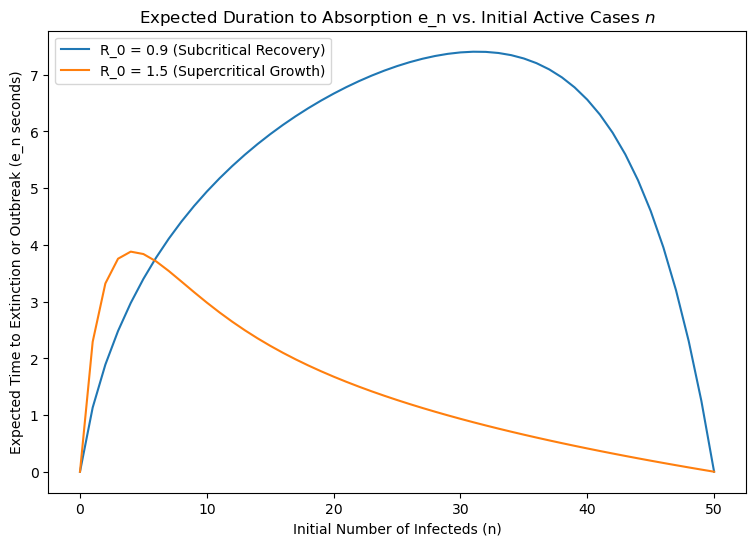

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

# Parameters
N = 1000
K = 50
beta = 0.002
delta_t = 0.01

def solve_expected_time(R0):
    gamma = (beta * N) / R0
    
    # matrix dimensions for inner states 1 to K-1
    size = K - 1
    n_states = np.arange(1, K)
    
    # transition rates
    p = beta * n_states * (N - n_states) * delta_t
    q = gamma * n_states * delta_t
    
    ab = np.zeros((3, size))
    
    ab[0, 1:] = p[:-1] # Upper diagonal
    ab[1, :]  = -(p + q) # Main diagonal
    ab[2, :-1] = q[1:] # Lower diagonal
    
    # right-hand side vector
    b = -np.ones(size) * delta_t
    
    # solve the tridiagonal matrix equation
    e_inner = solve_banded((1, 1), ab, b)
    
    return np.insert(np.append(e_inner, 0.0), 0, 0.0)

# calculate durations
e_subcritical = solve_expected_time(R0=0.9)
e_supercritical = solve_expected_time(R0=1.5)
states = np.arange(0, K + 1)

# visualization
plt.figure(figsize=(9, 6))
plt.plot(states, e_subcritical, label='R_0 = 0.9 (Subcritical Recovery)')
plt.plot(states, e_supercritical, label='R_0 = 1.5 (Supercritical Growth)')
plt.title('Expected Duration to Absorption e_n vs. Initial Active Cases $n$')
plt.xlabel('Initial Number of Infecteds (n)')
plt.ylabel('Expected Time to Extinction or Outbreak (e_n seconds)')
plt.legend()
plt.show()
